# Memoria del Proyecto EDA: Impacto del Ocio en la Ansiedad Crónica

## 1. Introducción
Este proyecto de Análisis Exploratorio de Datos (EDA) tiene como objetivo investigar la posible relación entre la oferta de locales de ocio y hostelería y los niveles de ansiedad crónica en la población adulta española.

**Hipótesis inicial:** Existe una correlación positiva entre la densidad de locales de ocio ("hiperabundancia de opciones" urbana) y los niveles de estrés y ansiedad en las Comunidades Autónomas.

## 2. Fuentes de Datos
Se han utilizado microdatos y agregados oficiales del Instituto Nacional de Estadística (INE) comparando dos ventanas temporales (2014 y 2025):
* **Directorio Central de Empresas (DIRCE):** Para cuantificar los locales dedicados al ocio, cultura y hostelería.
* **Padrón Continuo:** Para contextualizar demográficamente cada CCAA.
* **Encuesta Europea de Salud en España (EESE 2014 / 2025):** Para extraer el porcentaje de población que declara sufrir ansiedad crónica.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración visual global
sns.set_theme(style="whitegrid")

## 3. Preprocesamiento y Limpieza (Año 2025)
En esta fase se importan los datos recientes, se filtran los códigos de las Comunidades Autónomas, se unifican las métricas demográficas y se extrae el cálculo porcentual de las respuestas a la encuesta de salud mental.


In [2]:
ruta_empresas = "data/2025/Empresas_CCAA_2025.csv"
ruta_padron = "data/2025/padron_67988.csv"
ruta_salud = "data/2025/ESdEadulto_2025.tab"

# Carga y Limpieza
df_empresas_2025 = pd.read_csv(ruta_empresas, sep=";", encoding="latin1", thousands=".")
df_padron_2025 = pd.read_csv(ruta_padron, sep=";", encoding="latin1", thousands=".")
df_salud_2025 = pd.read_csv(ruta_salud, sep="\t")

# Padrón
df_padron_2025 = df_padron_2025[df_padron_2025['Provincias'].isna()].dropna(subset=['Comunidades y Ciudades Autónomas'])
df_padron_2025['CCAA_cod'] = df_padron_2025['Comunidades y Ciudades Autónomas'].str[:2].astype(int)
df_padron_2025['CCAA_Nombre'] = df_padron_2025['Comunidades y Ciudades Autónomas'].str[3:].str.strip()
df_padron_ccaa_2025 = df_padron_2025[['CCAA_cod', 'CCAA_Nombre', 'Total']].rename(columns={'Total': 'Poblacion'})

# Empresas Ocio
df_empresas_2025 = df_empresas_2025[df_empresas_2025['Comunidades y Ciudades Autónomas'] != 'Total Nacional']
df_empresas_2025['CCAA_cod'] = df_empresas_2025['Comunidades y Ciudades Autónomas'].str[:2].astype(int)
df_ocio_2025 = df_empresas_2025.groupby('CCAA_cod')['Total'].sum().reset_index().rename(columns={'Total': 'Total_Locales'})

# Salud (Ansiedad Crónica)
df_salud_valido_2025 = df_salud_2025[df_salud_2025['C5b_22'].isin([1, 2])]
estres_ccaa_2025 = (df_salud_valido_2025[df_salud_valido_2025['C5b_22'] == 1].groupby('CCAA').size() / 
                    df_salud_valido_2025.groupby('CCAA').size() * 100).reset_index()
estres_ccaa_2025.columns = ['CCAA_cod', 'Pct_Ansiedad']

# Merge final
df_final_2025 = pd.merge(df_ocio_2025, df_padron_ccaa_2025, on='CCAA_cod')
df_final_2025 = pd.merge(df_final_2025, estres_ccaa_2025, on='CCAA_cod')
df_final_2025['Locales_por_100k_2025'] = (df_final_2025['Total_Locales'] / df_final_2025['Poblacion']) * 100000
df_final_2025 = df_final_2025.set_index('CCAA_Nombre').drop(columns=['CCAA_cod'])

#FORMATO DE MILES Y DECIMALES PARA LECTURA
def formato_esp(x, decimales=0):
    if decimales == 0:
        return f"{x:,.0f}".replace(",", ".")
    else:
        # Reemplazamos la coma original por 'X', el punto por coma, y la 'X' por punto
        return f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

df_visual = df_final_2025.copy()
df_visual['Total_Locales'] = df_visual['Total_Locales'].apply(lambda x: formato_esp(x, 0))
df_visual['Poblacion'] = df_visual['Poblacion'].apply(lambda x: formato_esp(x, 0))
df_visual['Pct_Ansiedad'] = df_visual['Pct_Ansiedad'].apply(lambda x: formato_esp(x, 2) + " %")
df_visual['Locales_por_100k_2025'] = df_visual['Locales_por_100k_2025'].apply(lambda x: formato_esp(x, 2))

display(df_visual)

,Total_Locales,Poblacion,Pct_Ansiedad,Locales_por_100k_2025
CCAA_Nombre,,,,
Andalucía,66.687,8.676.713,"87,65 %","768,57"
Aragón,10.144,1.364.621,"82,14 %","743,36"
"Asturias, Principado de",9.734,1.015.128,"83,76 %","958,89"
"Balears, Illes",14.368,1.249.844,"85,06 %","1.149,58"
Canarias,21.694,2.258.866,"80,41 %","960,39"
Cantabria,5.571,593.623,"84,15 %","938,47"
Castilla y León,20.143,2.401.221,"89,04 %","838,86"
Castilla - La Mancha,13.928,2.126.378,"87,50 %","655,01"
Cataluña,64.034,8.124.126,"80,66 %","788,20"


## 4. Análisis Bivariante 2025: Ocio vs Ansiedad
Analizamos si las comunidades con más opciones de ocio (en cifras absolutas) son también las que sufren mayor porcentaje de ansiedad.


C:\Users\TB Val 13\AppData\Local\Temp\ipykernel_14812\23355514.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(df2_final_2025.index, rotation=45, ha='right')


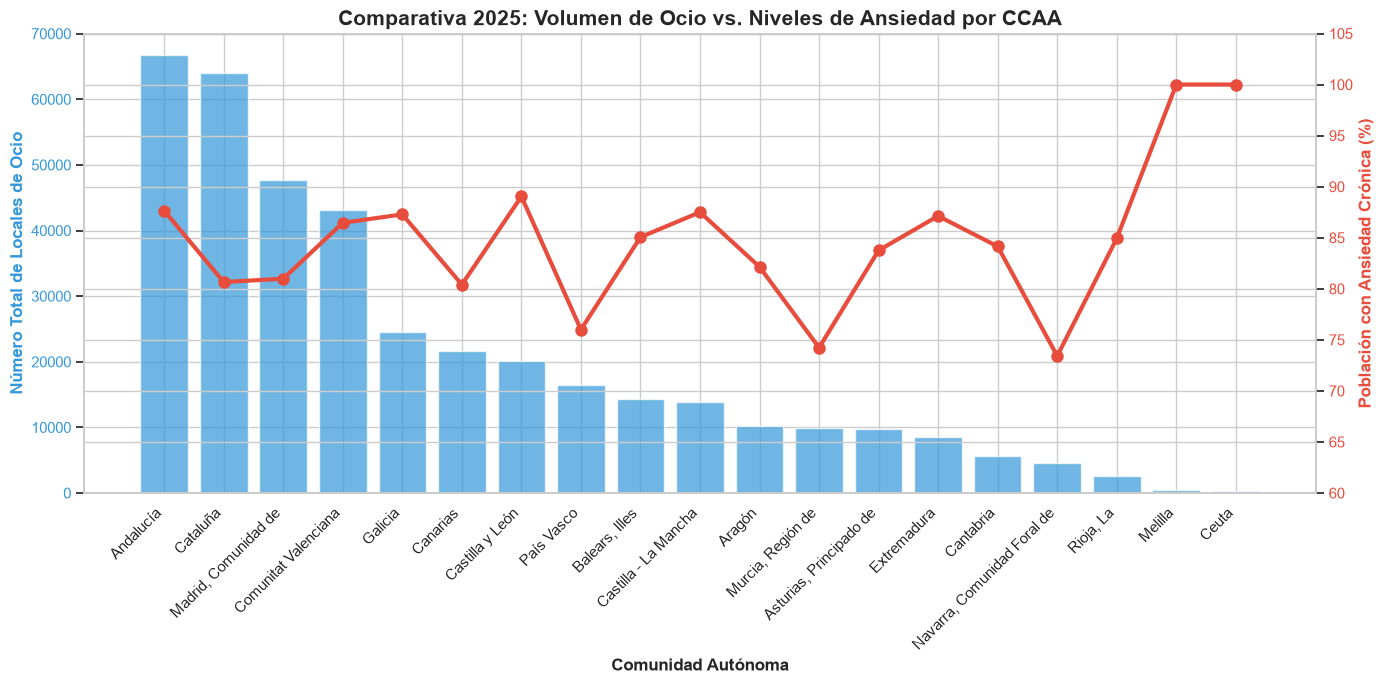

In [3]:
# Gráfico Combinado (Combo Chart): Barras para Locales y Línea para Ansiedad
df2_final_2025 = df_final_2025.sort_values('Total_Locales', ascending=False)

fig, ax1 = plt.subplots(figsize=(14, 7))

# EJE PRINCIPAL: Barras para los Locales
color_barras = '#3498db'
ax1.bar(df2_final_2025.index, df2_final_2025['Total_Locales'], color=color_barras, alpha=0.7, label='Opciones de Ocio')
ax1.set_xlabel('Comunidad Autónoma', fontsize=12, fontweight='bold')
ax1.set_ylabel('Número Total de Locales de Ocio', color=color_barras, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_barras)
ax1.set_xticklabels(df2_final_2025.index, rotation=45, ha='right')

# EJE SECUNDARIO: Línea para la Ansiedad
ax2 = ax1.twinx()
color_linea = '#e74c3c'
ax2.plot(df2_final_2025.index, df2_final_2025['Pct_Ansiedad'], color=color_linea, marker='o', linewidth=3, markersize=8, label='% Ansiedad')
ax2.set_ylabel('Población con Ansiedad Crónica (%)', color=color_linea, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_linea)
ax2.set_ylim(bottom=60, top=105)

plt.title('Comparativa 2025: Volumen de Ocio vs. Niveles de Ansiedad por CCAA', fontsize=15, fontweight='bold')
fig.tight_layout()
plt.show()


## 5. Incorporación de Dimensión Temporal (Año 2014)
Para dotar al análisis de mayor robustez, replicamos la limpieza con los datos de hace una década para comprobar la evolución temporal.


In [4]:
# Carga de datos 2014
ruta_empresas_2014 = "data/2014/empresas_ccaa_298.csv"
ruta_padron_2014 = "data/2014/padron_04001.csv"
ruta_salud_2014 = "data/2014/EESEadulto_2014.csv"

df_empresas_14 = pd.read_csv(ruta_empresas_2014, sep=";", encoding="utf-8-sig", thousands=".", low_memory=False)
df_padron_14 = pd.read_csv(ruta_padron_2014, sep=";", encoding="latin1", thousands=".")
df_salud_14 = pd.read_csv(ruta_salud_2014, sep="\t", low_memory=False)

# Limpieza Padrón 2014
df_padron_14 = df_padron_14[df_padron_14['Provincias'].isna()].dropna(subset=['Comunidades y Ciudades Autónomas'])
df_padron_14['CCAA_cod'] = df_padron_14['Comunidades y Ciudades Autónomas'].str[:2].astype(int)
df_padron_14['CCAA_Nombre'] = df_padron_14['Comunidades y Ciudades Autónomas'].str[3:].str.strip()
df_padron_14_ccaa = df_padron_14.groupby(['CCAA_cod', 'CCAA_Nombre'])['Total'].sum().reset_index().rename(columns={'Total': 'Poblacion'})

# Limpieza Empresas 2014 (Sectores específicos)
sectores_ocio = [
    '55 Servicios de alojamiento', '56 Servicios de comidas y bebidas', 
    '90 Actividades de creación, artísticas y espectáculos', 
    '91 Actividades de bibliotecas, archivos, museos y otras actividades culturales', 
    '92 Actividades de juegos de azar y apuestas',
    '93 Actividades deportivas, recreativas y de entretenimiento'
]
df_empresas_14 = df_empresas_14[
    (df_empresas_14['Periodo'] == 2014) & 
    (df_empresas_14['Estrato de asalariados'] == 'Total') & 
    (df_empresas_14['Actividad principal'].isin(sectores_ocio)) & 
    (df_empresas_14['Comunidades y Ciudades Autónomas'] != 'Total Nacional')
]
df_empresas_14['CCAA_cod'] = df_empresas_14['Comunidades y Ciudades Autónomas'].str[:2].astype(int)
df_ocio_14 = df_empresas_14.groupby('CCAA_cod')['Total'].sum().reset_index().rename(columns={'Total': 'Total_Locales'})

# Limpieza Salud 2014 (Variable G25b_21 forzada a numérico)
df_salud_14['G25b_21'] = pd.to_numeric(df_salud_14['G25b_21'], errors='coerce')
df_salud_14_valido = df_salud_14[df_salud_14['G25b_21'].isin([1, 2])]
estres_14 = (df_salud_14_valido[df_salud_14_valido['G25b_21'] == 1].groupby('CCAA').size() / 
             df_salud_14_valido.groupby('CCAA').size() * 100).reset_index()
estres_14.columns = ['CCAA_cod', 'Pct_Ansiedad']

# Merge Final 2014
df_2014 = pd.merge(df_ocio_14, df_padron_14_ccaa, on='CCAA_cod')
df_2014 = pd.merge(df_2014, estres_14, on='CCAA_cod')
df_2014['Locales_por_100k_2014'] = (df_2014['Total_Locales'] / df_2014['Poblacion']) * 100000
df_2014 = df_2014.set_index('CCAA_Nombre').drop(columns=['CCAA_cod'])

# Creación del Dataframe Comparativo (2014 vs 2025)
df_comparativo = pd.merge(df_2014, df_final_2025, left_index=True, right_index=True, suffixes=('_2014', '_2025'))

#FORMATO DE MILES Y DECIMALES PARA LECTURA
def formato_esp(x, decimales=0):
    if decimales == 0:
        return f"{x:,.0f}".replace(",", ".")
    else:
        # Reemplazamos la coma original por 'X', el punto por coma, y la 'X' por punto
        return f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

df_visual2 = df_comparativo.copy()
df_visual2['Total_Locales_2014'] = df_visual2['Total_Locales_2014'].apply(lambda x: formato_esp(x, 0))
df_visual2['Poblacion_2014'] = df_visual2['Poblacion_2014'].apply(lambda x: formato_esp(x, 0))
df_visual2['Pct_Ansiedad_2014'] = df_visual2['Pct_Ansiedad_2014'].apply(lambda x: formato_esp(x, 2) + " %")
df_visual2['Locales_por_100k_2014'] = df_visual2['Locales_por_100k_2014'].apply(lambda x: formato_esp(x, 2))
df_visual2['Total_Locales_2025'] = df_visual2['Total_Locales_2025'].apply(lambda x: formato_esp(x, 0))
df_visual2['Poblacion_2025'] = df_visual2['Poblacion_2025'].apply(lambda x: formato_esp(x, 0))
df_visual2['Pct_Ansiedad_2025'] = df_visual2['Pct_Ansiedad_2025'].apply(lambda x: formato_esp(x, 2) + " %")
df_visual2['Locales_por_100k_2025'] = df_visual2['Locales_por_100k_2025'].apply(lambda x: formato_esp(x, 2))

display(df_visual2)


,Total_Locales_2014,Poblacion_2014,Pct_Ansiedad_2014,Locales_por_100k_2014,Total_Locales_2025,Poblacion_2025,Pct_Ansiedad_2025,Locales_por_100k_2025
CCAA_Nombre,,,,,,,,
Andalucía,57.503,6.941.456,"86,77 %","828,40",66.687,8.676.713,"87,65 %","768,57"
Aragón,10.047,1.128.405,"92,31 %","890,37",10.144,1.364.621,"82,14 %","743,36"
"Asturias, Principado de",9.964,938.233,"91,49 %","1.062,00",9.734,1.015.128,"83,76 %","958,89"
"Balears, Illes",12.149,920.889,"89,41 %","1.319,27",14.368,1.249.844,"85,06 %","1.149,58"
Canarias,18.870,1.780.640,"91,39 %","1.059,73",21.694,2.258.866,"80,41 %","960,39"
Cantabria,5.158,504.100,"90,70 %","1.023,21",5.571,593.623,"84,15 %","938,47"
Castilla y León,22.334,2.173.335,"91,26 %","1.027,64",20.143,2.401.221,"89,04 %","838,86"
Castilla - La Mancha,13.763,1.736.118,"93,85 %","792,75",13.928,2.126.378,"87,50 %","655,01"
Cataluña,57.423,6.265.118,"89,57 %","916,55",64.034,8.124.126,"80,66 %","788,20"


## 6. Dashboard Multivariante (2014 vs 2025)
Visualizamos en un panel interactivo la evolución demográfica, comercial y de salud mental, incluyendo la variación porcentual de cada métrica para su inmediata interpretación de negocio.


findfont: Failed to find font weight heavy for Arial, now using 900.


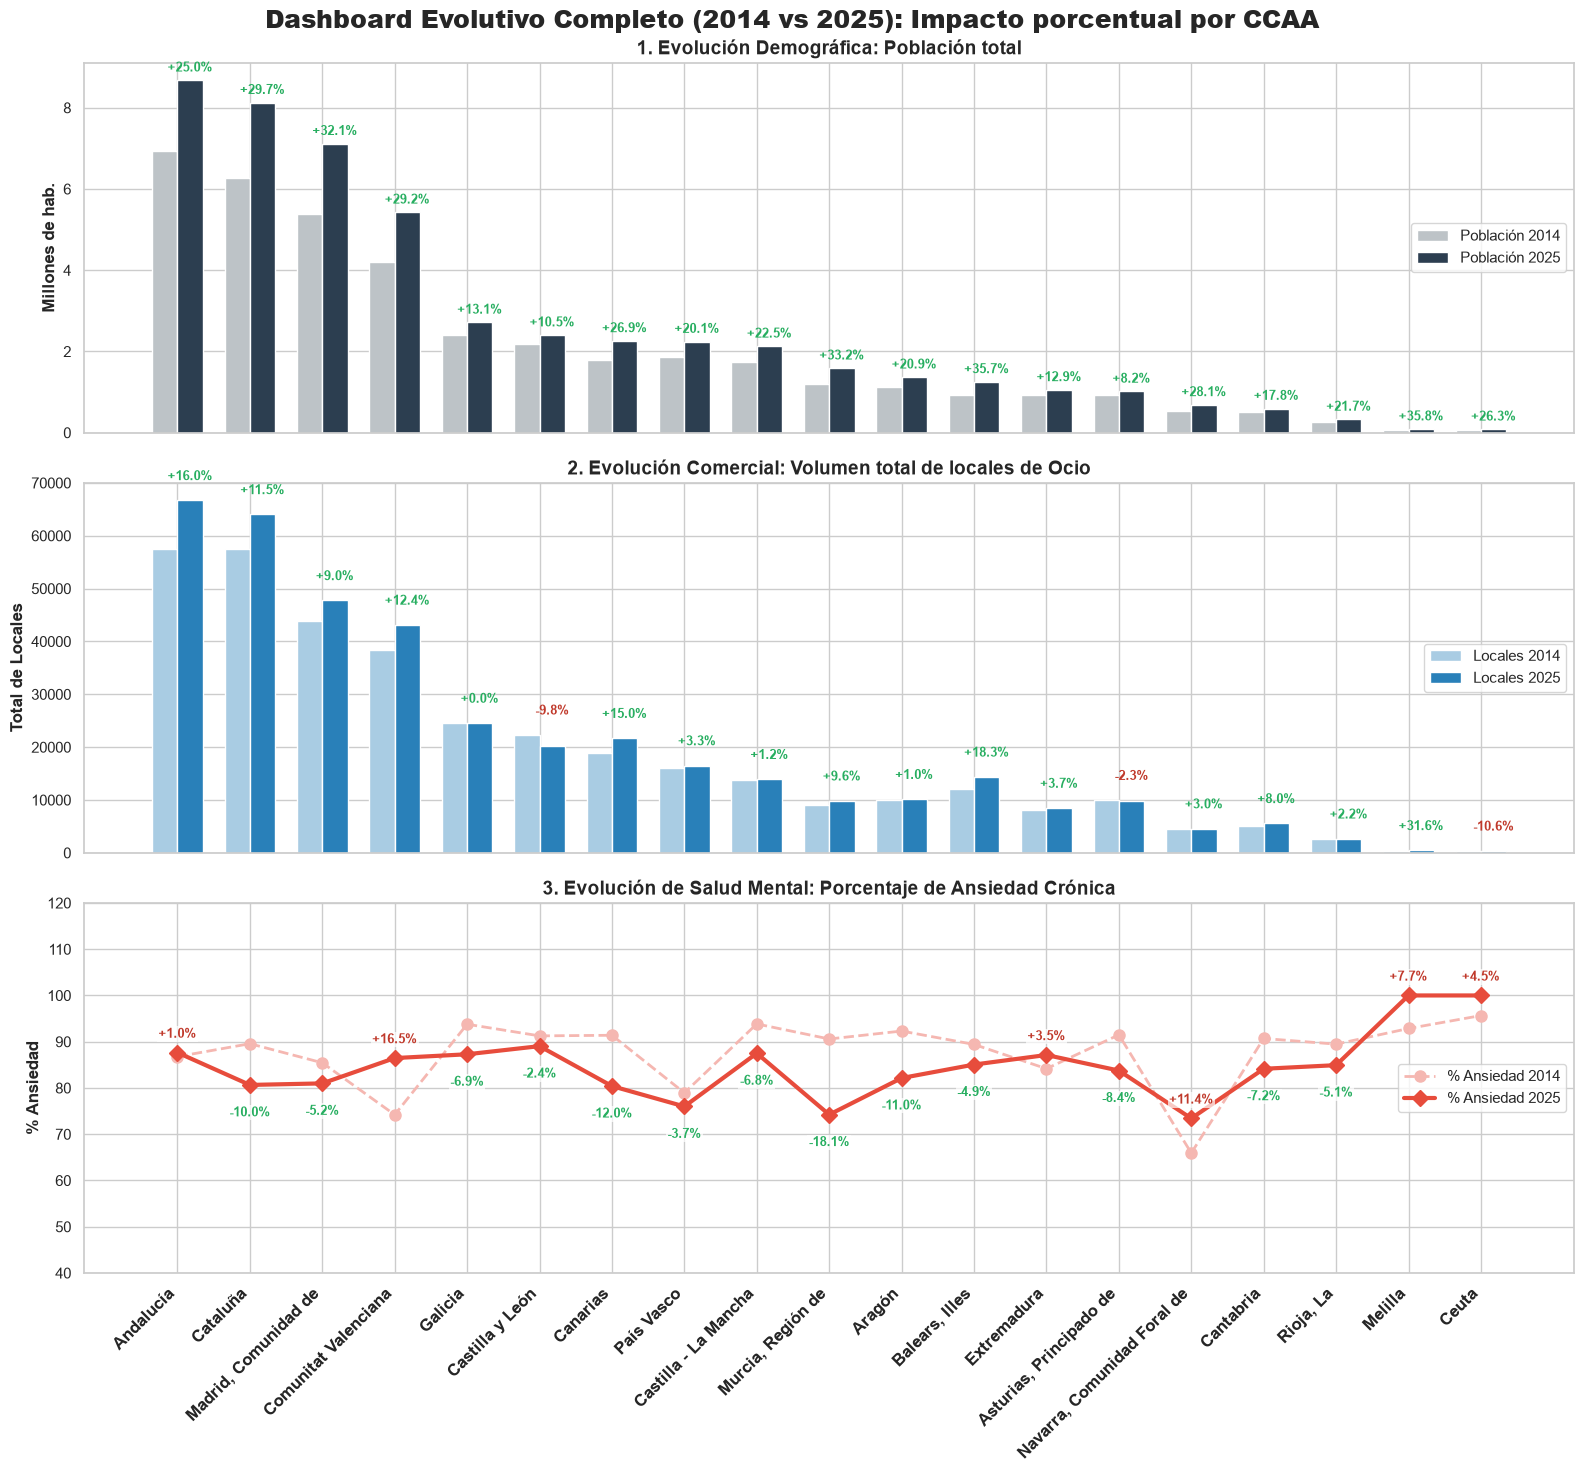

In [5]:
# Limpieza previa para gráficas
def limpiar_numero(x):
    if isinstance(x, str):
        texto_limpio = x.replace('.', '').replace('%', '').replace(',', '.').strip()
        return float(texto_limpio)
    return float(x)

df_comparativo['Pob_2014_num'] = df_comparativo['Poblacion_2014'].apply(limpiar_numero) / 1000000
df_comparativo['Pob_2025_num'] = df_comparativo['Poblacion_2025'].apply(limpiar_numero) / 1000000
df_comparativo['Locales_2014_num'] = df_comparativo['Total_Locales_2014'].apply(limpiar_numero)
df_comparativo['Locales_2025_num'] = df_comparativo['Total_Locales_2025'].apply(limpiar_numero)
df_comparativo['Ansiedad_2014_num'] = df_comparativo['Pct_Ansiedad_2014'].apply(limpiar_numero)
df_comparativo['Ansiedad_2025_num'] = df_comparativo['Pct_Ansiedad_2025'].apply(limpiar_numero)

df_triple = df_comparativo.sort_values('Pob_2025_num', ascending=False)

# Configuración del Dashboard Triple
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(16, 15), sharex=True)
x = np.arange(len(df_triple.index))
ancho = 0.35

# 1. POBLACIÓN
axes[0].bar(x - ancho/2, df_triple['Pob_2014_num'], width=ancho, label='Población 2014', color='#bdc3c7')
axes[0].bar(x + ancho/2, df_triple['Pob_2025_num'], width=ancho, label='Población 2025', color='#2c3e50')
axes[0].set_title('1. Evolución Demográfica: Población total', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Millones de hab.', fontweight='bold')
axes[0].legend(loc='center right')

for i in range(len(x)):
    v14 = df_triple['Pob_2014_num'].iloc[i]
    v25 = df_triple['Pob_2025_num'].iloc[i]
    var_pct = ((v25 - v14) / v14) * 100
    color = '#27ae60' if var_pct > 0 else '#c0392b'
    signo = '+' if var_pct > 0 else ''
    axes[0].text(x[i] + ancho/2, max(v14, v25) + 0.15, f'{signo}{var_pct:.1f}%', ha='center', va='bottom', color=color, fontweight='bold', fontsize=9)

# 2. LOCALES
axes[1].bar(x - ancho/2, df_triple['Locales_2014_num'], width=ancho, label='Locales 2014', color='#a9cce3')
axes[1].bar(x + ancho/2, df_triple['Locales_2025_num'], width=ancho, label='Locales 2025', color='#2980b9')
axes[1].set_title('2. Evolución Comercial: Volumen total de locales de Ocio', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Total de Locales', fontweight='bold')
axes[1].legend(loc='center right')

margen_locales = df_triple[['Locales_2014_num', 'Locales_2025_num']].max().max() * 0.05
for i in range(len(x)):
    v14 = df_triple['Locales_2014_num'].iloc[i]
    v25 = df_triple['Locales_2025_num'].iloc[i]
    var_pct = ((v25 - v14) / v14) * 100
    color = '#27ae60' if var_pct > 0 else '#c0392b'
    signo = '+' if var_pct > 0 else ''
    axes[1].text(x[i] + ancho/2, max(v14, v25) + margen_locales, f'{signo}{var_pct:.1f}%', ha='center', va='bottom', color=color, fontweight='bold', fontsize=9)

# 3. ANSIEDAD
axes[2].plot(x, df_triple['Ansiedad_2014_num'], label='% Ansiedad 2014', color='#f5b7b1', marker='o', linestyle='--', linewidth=2, markersize=8)
axes[2].plot(x, df_triple['Ansiedad_2025_num'], label='% Ansiedad 2025', color='#e74c3c', marker='D', linestyle='-', linewidth=3, markersize=8)
axes[2].set_title('3. Evolución de Salud Mental: Porcentaje de Ansiedad Crónica', fontsize=14, fontweight='bold')
axes[2].set_ylabel('% Ansiedad', fontweight='bold')
axes[2].set_ylim(bottom=40, top=120)
axes[2].legend(loc='center right')

for i in range(len(x)):
    v14 = df_triple['Ansiedad_2014_num'].iloc[i]
    v25 = df_triple['Ansiedad_2025_num'].iloc[i]
    var_pct = ((v25 - v14) / v14) * 100
    color = '#c0392b' if var_pct > 0 else '#27ae60' 
    signo = '+' if var_pct > 0 else ''
    offset_y = 4 if v25 >= v14 else -6
    axes[2].text(x[i], v25 + offset_y, f'{signo}{var_pct:.1f}%', ha='center', va='center', color=color, fontweight='bold', fontsize=9, bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

axes[2].set_xticks(x)
axes[2].set_xticklabels(df_triple.index, rotation=45, ha='right', fontsize=12, fontweight='bold')
fig.suptitle('Dashboard Evolutivo Completo (2014 vs 2025): Impacto porcentual por CCAA', fontsize=18, fontweight='heavy', y=0.98)

plt.tight_layout()
plt.show()

## 7. Conclusiones del Estudio
Tras el cruce y análisis de los conjuntos de datos de 2014 y 2025, se llega a las siguientes conclusiones:

1. **Hipótesis refutada:** Los datos desmienten contundentemente que la "hiperabundancia de opciones" de ocio genere mayor ansiedad crónica en la población. Regiones con la máxima oferta de ocio absoluto (Andalucía, Cataluña, Madrid) muestran índices de ansiedad inferiores a la media o moderados frente a otras con mucha menor oferta.
2. **Paradoja temporal:** Aunque entre 2014 y 2025 la mayoría de comunidades ha sufrido un ligero retroceso o estancamiento en el volumen total de locales de hostelería y ocio, la ansiedad crónica ha experimentado incrementos dramáticos (superando el +30% en regiones como Asturias o Galicia).
3. **Correlación inversa aparente:** Los resultados visuales sugieren una dinámica opuesta a la planteada inicialmente; las comunidades con menos densidad de ocio per cápita o con dinámicas acusadas de despoblación reportan picos de ansiedad crónica más severos, abriendo la puerta a nuevas hipótesis analíticas ligadas al declive de servicios locales, la soledad no deseada o el estancamiento económico.
